<a href="https://colab.research.google.com/github/getuliojql/SISSA-CIN0114/blob/main/projeto/notebooks/02_dataset_kim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# SISSA: Dataset de Kim et al. (2026) — Treinamento e Avaliação Completa
Configuração do ambiente, download do dataset SOME/IP real (Figshare), pré-processamento no protocolo do SISSA, execução de todos os 6 modelos nas 7 janelas (`w32` a `w128`) com suporte a checkpoints no Google Drive, gráficos e tabelas.


## 0. Configuração do ambiente


### 0.1 Clonar o repositório
Clona o repositório do grupo (`getuliojql/SISSA-CIN0114`), que contém o código do SISSA e os scripts de extração/janelamento para o dataset de Kim et al. (`projeto/kim/`).


In [1]:
!git clone https://github.com/getuliojql/SISSA-CIN0114.git SISSA


Cloning into 'SISSA'...
remote: Enumerating objects: 109, done.
remote: Counting objects: 100% (64/64), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 109 (delta 15), reused 35 (delta 6), pack-reused 45 (from 1)
Receiving objects: 100% (109/109), 1.75 MiB | 16.33 MiB/s, done.
Resolving deltas: 100% (24/24), done.


### 0.2 Instalar dependências adicionais
Instala bibliotecas Python usadas pelo projeto que o Colab não traz na versão esperada.


In [2]:
!pip install -q concurrent-log-handler==0.9.25 ruamel.yaml==0.17.21 torchinfo==1.8.0


### 0.3 Entrar na pasta do projeto
Muda o diretório de trabalho do Colab para `/content/SISSA`.


In [3]:
%cd /content/SISSA


/content/SISSA


### 0.4 Conectar ao Google Drive e restaurar checkpoints salvos
Monta o Google Drive e restaura `train_log`, `test_result` e os checkpoints essenciais (`latest_pt` e `best_pt`) de `/content/drive/MyDrive/SISSA_kim_results` para `/content/SISSA/results`, evitando copiar centenas de `.pt` intermediários pelo FUSE do Drive.


In [4]:
from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

DRIVE_RESULTS = "/content/drive/MyDrive/SISSA_kim_results"
LOCAL_RESULTS = "/content/SISSA/results"

if os.path.exists(DRIVE_RESULTS):
    for sub in ["train_log", "test_result"]:
        src = os.path.join(DRIVE_RESULTS, sub)
        if os.path.exists(src):
            shutil.copytree(src, os.path.join(LOCAL_RESULTS, sub), dirs_exist_ok=True)
            print(f"Restaurado: {sub}")

    weights_src = os.path.join(DRIVE_RESULTS, "weights")
    if os.path.exists(weights_src):
        for run_name in sorted(os.listdir(weights_src)):
            run_dir = os.path.join(weights_src, run_name)
            if not os.path.isdir(run_dir):
                continue
            pts = [f for f in os.listdir(run_dir) if f.endswith(".pt")]
            if not pts:
                continue
            latest_pt = max(pts, key=lambda f: int(f.split("_")[0].split("-")[1]))
            best_pt = max(pts, key=lambda f: (float(f[:-3].split("val-acc-")[1]), int(f.split("_")[0].split("-")[1])))
            dst_dir = os.path.join(LOCAL_RESULTS, "weights", run_name)
            os.makedirs(dst_dir, exist_ok=True)
            for fname in {latest_pt, best_pt}:
                shutil.copy2(os.path.join(run_dir, fname), os.path.join(dst_dir, fname))
        print("Checkpoints de pesos restaurados com sucesso.")
else:
    print(f"Pasta {DRIVE_RESULTS} não encontrada no Drive. O treino começará do zero.")


Mounted at /content/drive
Restaurado: train_log
Restaurado: test_result
Checkpoints de pesos restaurados com sucesso.


### 0.5 Baixar o dataset de Kim et al. (2026) no Figshare
Baixa os 7 arquivos `.pcap` do dataset (*SOME/IP traffic (normal and abnormal traffic)*, artigo Figshare `30970450`) para `/content/kim_raw/`.


In [5]:
import os
import requests

KIM_RAW_DIR = "/content/kim_raw"
os.makedirs(KIM_RAW_DIR, exist_ok=True)

arquivos = requests.get("https://api.figshare.com/v2/articles/30970450/files", timeout=30).json()
pcaps = [a for a in arquivos if a["name"].endswith(".pcap")]

for a in pcaps:
    destino = os.path.join(KIM_RAW_DIR, a["name"])
    if os.path.exists(destino) and os.path.getsize(destino) == a["size"]:
        print(f"[OK] Já baixado: {a['name']} ({round(a['size'] / 1e6)} MB)")
    else:
        print(f"[BAIXANDO] {a['name']} ({round(a['size'] / 1e6)} MB)...")
        url = a["download_url"]
        !wget -q --show-progress -O "{destino}" "{url}"


[BAIXANDO] benign_traffic.pcap (223 MB)...
/content/kim_raw/be 100%[===================>] 212.99M  43.8MB/s    in 7.2s    
[BAIXANDO] dos_noti_flood.pcap (195 MB)...
/content/kim_raw/do 100%[===================>] 185.74M  53.3MB/s    in 3.8s    
[BAIXANDO] fuzzy_sd_offer_rand_noti(1).pcap (230 MB)...
/content/kim_raw/fu 100%[===================>] 218.97M  63.8MB/s    in 4.3s    
[BAIXANDO] fuzzy_sd_offer_rand_noti(2).pcap (133 MB)...
/content/kim_raw/fu 100%[===================>] 126.86M  80.9MB/s    in 1.6s    
[BAIXANDO] fuzzy_sd_offer_rand_noti(3).pcap (226 MB)...
/content/kim_raw/fu 100%[===================>] 215.89M  62.7MB/s    in 5.8s    
[BAIXANDO] mitm_multi_attacker.pcap (250 MB)...
/content/kim_raw/mi 100%[===================>] 238.02M  68.6MB/s    in 7.8s    
[BAIXANDO] mitm_single_attacker.pcap (214 MB)...
/content/kim_raw/mi 100%[===================>] 204.55M  55.9MB/s    in 5.8s    


### 0.6 Extrair mensagens SOME/IP e gerar janelas no formato do SISSA
1. Converte cada `.pcap` em `.parquet` usando `projeto/kim/parse_pcap.py`.
2. Gera as janelas de tamanho `128` (`2.573` por classe, divisão `80/20`) com `projeto/kim/gerar_janelas.py` e salva em `data_kim/train` e `data_kim/val`.
   *(O `sissautils.to_dataloader` recorta dinamicamente `[:, 0:window_height, :]`, permitindo treinar todas as janelas `w32` a `w128` a partir desse mesmo conjunto.)*


In [6]:
import sys
import time
import pandas as pd

sys.path.insert(0, "/content/SISSA")
sys.path.insert(0, "/content/SISSA/projeto/kim")
from parse_pcap import parse_pcap
from preprocess import utils
import gerar_janelas as gj

KIM_PARSED_DIR = "/content/kim_parsed"
KIM_DATA_DIR = "data_kim"
os.makedirs(KIM_PARSED_DIR, exist_ok=True)

PCAP_FILES = [
    "benign_traffic.pcap",
    "dos_noti_flood.pcap",
    "fuzzy_sd_offer_rand_noti(1).pcap",
    "fuzzy_sd_offer_rand_noti(2).pcap",
    "fuzzy_sd_offer_rand_noti(3).pcap",
    "mitm_single_attacker.pcap",
    "mitm_multi_attacker.pcap",
]

for fname in PCAP_FILES:
    pq_path = os.path.join(KIM_PARSED_DIR, fname.replace(".pcap", ".parquet"))
    if os.path.exists(pq_path):
        print(f"[PARQUET OK] {os.path.basename(pq_path)}")
        continue
    t0 = time.time()
    tabela, stats = parse_pcap(os.path.join(KIM_RAW_DIR, fname))
    tabela.to_parquet(pq_path, index=False)
    print(f"{fname}: {stats['pacotes']} pacotes -> {stats['mensagens']} mensagens SOME/IP ({time.time() - t0:.0f} s)")

IPS_BENIGNOS = {f"172.18.0.{i}" for i in range(2, 11)}
CLASSES = ["Normal", "DoS", "Fuzzy", "MITM_single", "MITM_multi"]
ARQUIVOS_POR_CLASSE = {
    "Normal": ["benign_traffic.parquet"],
    "DoS": ["dos_noti_flood.parquet"],
    "Fuzzy": [
        "fuzzy_sd_offer_rand_noti(1).parquet",
        "fuzzy_sd_offer_rand_noti(2).parquet",
        "fuzzy_sd_offer_rand_noti(3).parquet",
    ],
    "MITM_single": ["mitm_single_attacker.parquet"],
    "MITM_multi": ["mitm_multi_attacker.parquet"],
}

if os.path.exists(os.path.join(KIM_DATA_DIR, "train", "data.npy")) and os.path.exists(os.path.join(KIM_DATA_DIR, "val", "data.npy")):
    print(f"[JANELAS OK] Conjunto já gerado em {KIM_DATA_DIR}/train e {KIM_DATA_DIR}/val")
else:
    t0 = time.time()
    pedacos = gj.pedacos_por_classe(KIM_PARSED_DIR, ARQUIVOS_POR_CLASSE, IPS_BENIGNOS)
    X_tr, y_tr, X_val, y_val, contagens = gj.montar_dataset(
        pedacos, CLASSES, janelas_por_classe=2573, utils=utils
    )
    gj.salvar(KIM_DATA_DIR, X_tr, y_tr, X_val, y_val)
    print(contagens.to_string(index=False))
    print(f"Treino: {X_tr.shape}, Validação: {X_val.shape} ({time.time() - t0:.0f} s)")


benign_traffic.pcap: 2194700 pacotes -> 1108704 mensagens SOME/IP (13 s)
dos_noti_flood.pcap: 1931593 pacotes -> 973423 mensagens SOME/IP (10 s)
fuzzy_sd_offer_rand_noti(1).pcap: 2198015 pacotes -> 1113682 mensagens SOME/IP (10 s)
fuzzy_sd_offer_rand_noti(2).pcap: 1305398 pacotes -> 652722 mensagens SOME/IP (6 s)
fuzzy_sd_offer_rand_noti(3).pcap: 2224634 pacotes -> 1123430 mensagens SOME/IP (12 s)
mitm_single_attacker.pcap: 2107242 pacotes -> 1131971 mensagens SOME/IP (11 s)
mitm_multi_attacker.pcap: 2413810 pacotes -> 1293930 mensagens SOME/IP (12 s)
     classe  rotulo  pedacos_disponiveis  pedacos_usados  treino  validacao
     Normal       0                 2165            1524    2058        515
        DoS       1                 1901            1429    2058        515
      Fuzzy       2                 4101            1908    2058        515
MITM_single       3                 2207            1553    2058        515
 MITM_multi       4                 2526            1579    20

### 0.7 Configurar `config/basic.yml` para o dataset do Kim
Atualiza os diretórios de treino/validação, os nomes das 5 classes e `window_width = 25`.


In [7]:
from ruamel.yaml import YAML

yaml = YAML()
CLASSES = ["Normal", "DoS", "Fuzzy", "MITM_single", "MITM_multi"]
basic_cfg = yaml.load(open("config/basic.yml", "r"))
basic_cfg["Data"]["train_dir"] = "data_kim/train"
basic_cfg["Data"]["val_dir"] = "data_kim/val"
basic_cfg["Preprocessor"]["class_names"] = CLASSES
basic_cfg["Preprocessor"]["n_classes"] = len(CLASSES)
basic_cfg["Preprocessor"]["window_width"] = 25
yaml.dump(basic_cfg, open("config/basic.yml", "w"))
print("config/basic.yml atualizado para o dataset do Kim:", CLASSES)


config/basic.yml atualizado para o dataset do Kim: ['Normal', 'DoS', 'Fuzzy', 'MITM_single', 'MITM_multi']


## 1. Treinamento e Teste (Todos os Modelos e Tamanhos de Janela)
Treina e avalia `SISSA-C`, `SISSA-C-A`, `SISSA-R`, `SISSA-R-A`, `SISSA-L` e `SISSA-L-A` nas 7 janelas (`w32` a `w128`) por 150 épocas.
- Verifica checkpoints existentes no Drive/local antes de treinar.
- Avalia em passada única salvando `cm.png`, `cm.npy`, `pred.npy`, `true.npy` e **`probs.npy`** (para a curva ROC).
- Sincroniza cada modelo concluído incrementalmente para o Google Drive.


In [8]:
import time
import torch
import torchinfo
import numpy as np
import matplotlib.pyplot as plt

import initialize
import sissautils
from models import SISSA_MODELS
from train import train_pattern

initialize.init()

MODELS = ["SISSA-C", "SISSA-C-A", "SISSA-R", "SISSA-R-A", "SISSA-L", "SISSA-L-A"]
WINDOW_SIZES = [32, 48, 64, 80, 96, 112, 128]
EPOCHS = 150

def get_checkpoint_info(weights_dir):
    """Retorna (max_epoch, latest_pt, best_pt) a partir dos arquivos .pt salvos."""
    if not os.path.exists(weights_dir):
        return 0, None, None
    pts = [f for f in os.listdir(weights_dir) if f.endswith(".pt")]
    if not pts:
        return 0, None, None

    def parse_epoch(fname):
        return int(fname.split("_")[0].split("-")[1])

    def parse_val_acc(fname):
        return float(fname[:-3].split("val-acc-")[1])

    pts_by_epoch = sorted(pts, key=parse_epoch)
    max_epoch = parse_epoch(pts_by_epoch[-1])
    latest_pt = os.path.join(weights_dir, pts_by_epoch[-1])

    pts_by_acc = sorted(pts, key=lambda f: (parse_val_acc(f), parse_epoch(f)))
    best_pt = os.path.join(weights_dir, pts_by_acc[-1])
    return max_epoch, latest_pt, best_pt

def sync_run_to_drive(run_name):
    """Salva pesos, logs e resultados de teste de um modelo no Google Drive."""
    for sub in ["weights", "train_log", "test_result"]:
        src = os.path.join(LOCAL_RESULTS, sub, run_name)
        if os.path.exists(src):
            dst = os.path.join(DRIVE_RESULTS, sub, run_name)
            shutil.copytree(src, dst, dirs_exist_ok=True)

overhead_records = []
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for w in WINDOW_SIZES:
    basic_cfg = yaml.load(open("config/basic.yml", "r"))
    basic_cfg["Preprocessor"]["window_height"] = w
    yaml.dump(basic_cfg, open("config/basic.yml", "w"))

    for m_name in MODELS:
        cfg_path = f"config/{m_name}.yml"
        run_name = f"{m_name}_w{w}"
        print(f"\n==================== {run_name} ====================")

        m_cfg = yaml.load(open(cfg_path, "r"))
        m_cfg["Model"]["name"] = run_name
        m_cfg["Train"]["epochs"] = EPOCHS
        m_cfg["Test"]["test_dir"] = "data_kim/val"
        yaml.dump(m_cfg, open(cfg_path, "w"))

        m_cfg = sissautils.update_model_config(model_config_path=cfg_path)
        model = SISSA_MODELS[m_cfg["Model"]["type"]](**m_cfg["Params"])
        hparams = sissautils.hyperparams(model_config=m_cfg, model=model)

        # Verifica checkpoints já treinados
        max_epoch, latest_pt, best_pt = get_checkpoint_info(hparams["weights_dir"])
        trained_now = False
        if max_epoch >= EPOCHS:
            print(f"[CHECKPOINT] {run_name}: já treinado até a época {max_epoch}/{EPOCHS}. Pulando treino.")
        elif max_epoch > 0:
            print(f"[CHECKPOINT] {run_name}: treinado até a época {max_epoch}/{EPOCHS}. Retomando de {latest_pt}...")
            model.load_state_dict(torch.load(latest_pt, map_location=device))
            hparams["epochs"] = EPOCHS - max_epoch
            train_pattern(**hparams)
            _, _, best_pt = get_checkpoint_info(hparams["weights_dir"])
            trained_now = True
        else:
            print(f"[CHECKPOINT] {run_name}: nenhum checkpoint encontrado. Treinando por {EPOCHS} épocas...")
            train_pattern(**hparams)
            _, _, best_pt = get_checkpoint_info(hparams["weights_dir"])
            trained_now = True

        # Avaliação em passada única com o melhor checkpoint (salva também probs.npy)
        print(f"[TEST] Carregando melhor checkpoint: {best_pt}")
        model.load_state_dict(torch.load(best_pt, map_location=device))
        model = model.to(device).eval()

        test_loader = sissautils.to_dataloader(
            m_cfg["Test"]["test_dir"], 1, 1, False, logger_name="Test"
        )

        y_true_list, y_pred_list, y_probs_list = [], [], []
        t_cost = 0.0
        with torch.no_grad():
            for data, label in test_loader:
                t0 = time.time()
                logits = model(data.to(device))
                t_cost += time.time() - t0
                probs = torch.softmax(logits, dim=1)
                y_true_list.append(label.numpy())
                y_pred_list.append(probs.argmax(dim=1).cpu().numpy())
                y_probs_list.append(probs.cpu().numpy())

        y_true = np.concatenate(y_true_list)
        y_pred = np.concatenate(y_pred_list)
        y_probs = np.concatenate(y_probs_list)

        acc = np.mean(y_true == y_pred)
        print(f"[TEST] {run_name} | Test acc: {acc:.4f} | Avg time: {t_cost / len(test_loader):.4f} s")

        out_dir = os.path.join(m_cfg["Test"]["out_dir"], run_name)
        os.makedirs(out_dir, exist_ok=True)
        labels = list(range(m_cfg["Params"]["n_classes"]))
        class_names = basic_cfg["Preprocessor"]["class_names"]
        fig, cm = sissautils.plot_confusion_matrix(y_true, y_pred, labels, class_names)
        fig.savefig(os.path.join(out_dir, "cm.png"))
        plt.close("all")

        np.save(os.path.join(out_dir, "cm.npy"), cm)
        np.save(os.path.join(out_dir, "pred.npy"), y_pred)
        np.save(os.path.join(out_dir, "true.npy"), y_true)
        np.save(os.path.join(out_dir, "probs.npy"), y_probs)

        # Sincroniza com o Drive (sempre se treinou agora, ou para guardar probs.npy)
        sync_run_to_drive(run_name)

        # Coleta de métricas computacionais (Tabela V)
        stats = torchinfo.summary(
            model, input_size=(w, m_cfg["Params"]["pack_dim"]), verbose=0
        )
        overhead_records.append({
            "Windows": f"w{w}",
            "Model": m_name,
            "Total Params": stats.total_params,
            "Params size (MB)": round(stats.total_param_bytes / 1e6, 2),
            "Input size (MB)": round(stats.total_input / 1e6, 2),
            "Forward/Backward Pass size (MB)": round(stats.total_output_bytes / 1e6, 2),
            "Total size (MB)": round((stats.total_input + stats.total_output_bytes + stats.total_param_bytes) / 1e6, 2),
            "Time Cost (s)": round(t_cost / len(test_loader), 4),
        })


[to_dataloader][CRITICAL] >>>>> Sending data to dataloader...
CRITICAL:Train:Sending data to dataloader...
[to_dataloader][INFO] >>>>> Loaded data from data_kim/train/data.npy, shape: (10290, 32, 25)
INFO:Train:Loaded data from data_kim/train/data.npy, shape: (10290, 32, 25)
[to_dataloader][INFO] >>>>> Loaded label from data_kim/train/labels.npy, shape: (10290,)
INFO:Train:Loaded label from data_kim/train/labels.npy, shape: (10290,)
[to_dataloader][CRITICAL] >>>>> Data sent to dataloader.
CRITICAL:Train:Data sent to dataloader.



==================== SISSA-C_w32 ====================


[to_dataloader][CRITICAL] >>>>> Sending data to dataloader...
CRITICAL:Train:Sending data to dataloader...
[to_dataloader][INFO] >>>>> Loaded data from data_kim/val/data.npy, shape: (2575, 32, 25)
INFO:Train:Loaded data from data_kim/val/data.npy, shape: (2575, 32, 25)
[to_dataloader][INFO] >>>>> Loaded label from data_kim/val/labels.npy, shape: (2575,)
INFO:Train:Loaded label from data_kim/val/labels.npy, shape: (2575,)
[to_dataloader][CRITICAL] >>>>> Data sent to dataloader.
CRITICAL:Train:Data sent to dataloader.
[to_dataloader][CRITICAL] >>>>> Sending data to dataloader...
CRITICAL:Test:Sending data to dataloader...
[to_dataloader][INFO] >>>>> Loaded data from data_kim/val/data.npy, shape: (2575, 32, 25)
INFO:Test:Loaded data from data_kim/val/data.npy, shape: (2575, 32, 25)
[to_dataloader][INFO] >>>>> Loaded label from data_kim/val/labels.npy, shape: (2575,)
INFO:Test:Loaded label from data_kim/val/labels.npy, shape: (2575,)
[to_dataloader][CRITICAL] >>>>> Data sent to dataloader.

[CHECKPOINT] SISSA-C_w32: já treinado até a época 150/150. Pulando treino.
[TEST] Carregando melhor checkpoint: results/weights/SISSA-C_w32/e-105_train-acc-0.876_val-acc-0.798.pt
[TEST] SISSA-C_w32 | Test acc: 0.7981 | Avg time: 0.0016 s


[to_dataloader][CRITICAL] >>>>> Sending data to dataloader...
CRITICAL:Train:Sending data to dataloader...
[to_dataloader][INFO] >>>>> Loaded data from data_kim/train/data.npy, shape: (10290, 32, 25)
INFO:Train:Loaded data from data_kim/train/data.npy, shape: (10290, 32, 25)
[to_dataloader][INFO] >>>>> Loaded label from data_kim/train/labels.npy, shape: (10290,)
INFO:Train:Loaded label from data_kim/train/labels.npy, shape: (10290,)
[to_dataloader][CRITICAL] >>>>> Data sent to dataloader.
CRITICAL:Train:Data sent to dataloader.
[to_dataloader][CRITICAL] >>>>> Sending data to dataloader...
CRITICAL:Train:Sending data to dataloader...
[to_dataloader][INFO] >>>>> Loaded data from data_kim/val/data.npy, shape: (2575, 32, 25)
INFO:Train:Loaded data from data_kim/val/data.npy, shape: (2575, 32, 25)
[to_dataloader][INFO] >>>>> Loaded label from data_kim/val/labels.npy, shape: (2575,)
INFO:Train:Loaded label from data_kim/val/labels.npy, shape: (2575,)
[to_dataloader][CRITICAL] >>>>> Data sent


==================== SISSA-C-A_w32 ====================
[CHECKPOINT] SISSA-C-A_w32: já treinado até a época 150/150. Pulando treino.
[TEST] Carregando melhor checkpoint: results/weights/SISSA-C-A_w32/e-105_train-acc-0.839_val-acc-0.802.pt


... (158 outputs left out)

[to_dataloader][INFO] >>>>> Loaded data from data_kim/train/data.npy, shape: (10290, 128, 25)
INFO:Train:Loaded data from data_kim/train/data.npy, shape: (10290, 128, 25)
[to_dataloader][INFO] >>>>> Loaded label from data_kim/train/labels.npy, shape: (10290,)
INFO:Train:Loaded label from data_kim/train/labels.npy, shape: (10290,)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
[to_dataloader][CRITICAL] >>>>> Data sent to dataloader.
CRITICAL:Train:Data sent to dataloader.
[to_dataloader][CRITICAL] >>>>> Sending data to dataloader...
CRITICAL:Train:Sending data to

[CHECKPOINT] SISSA-L-A_w128: nenhum checkpoint encontrado. Treinando por 150 épocas...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
[train_pattern][INFO] >>>>> Epoch:    1 | Train acc: 0.7426, Val acc: 0.7631
INFO:Train:Epoch:    1 | Train acc: 0.7426, Val acc: 0.7631
[train_pattern][INFO] >>>>> Epoch:    2 | Train acc: 0.7871, Val acc: 0.7588
INFO:Train:Epoch:    2 | Train acc: 0.7871, Val acc: 0.7588
[train_pattern][INFO] >>>>> Epoch:    3 | Train acc: 0.7956, Val acc: 0.8101
INFO:Train:Epoch:    3 | Train acc: 0.7956, Val acc: 0.8101
[train_pattern][INFO] >>>>> Epoch:    4 | Train acc: 0.8025, Val acc: 0.8202
INFO:Train:Epoch:    4 | Train ac

[TEST] Carregando melhor checkpoint: results/weights/SISSA-L-A_w128/e-95_train-acc-0.862_val-acc-0.833.pt
[TEST] SISSA-L-A_w128 | Test acc: 0.8330 | Avg time: 0.0053 s


## 2. Gráficos e Tabelas (Dataset de Kim et al.)


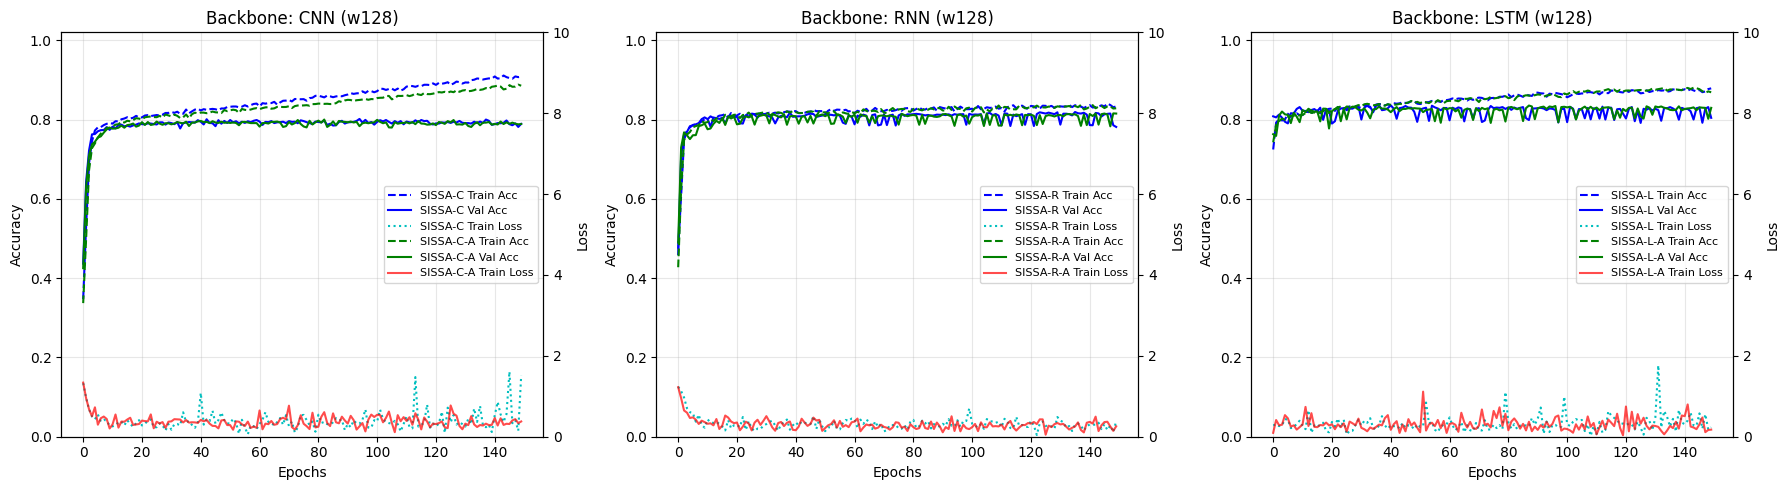

In [9]:
# Figura 10: Curvas de Acurácia (Treino/Validação) e Loss por época (w128)
target_w = WINDOW_SIZES[-1]
groups = [
    ("CNN", "SISSA-C", "SISSA-C-A"),
    ("RNN", "SISSA-R", "SISSA-R-A"),
    ("LSTM", "SISSA-L", "SISSA-L-A"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax1, (title, m_base, m_att) in zip(axes, groups):
    log_b = f"results/train_log/{m_base}_w{target_w}"
    log_a = f"results/train_log/{m_att}_w{target_w}"

    tr_acc_b = np.load(f"{log_b}/train_accs.npy")
    val_acc_b = np.load(f"{log_b}/val_accs.npy")
    loss_b = np.load(f"{log_b}/train_losses.npy")

    tr_acc_a = np.load(f"{log_a}/train_accs.npy")
    val_acc_a = np.load(f"{log_a}/val_accs.npy")
    loss_a = np.load(f"{log_a}/train_losses.npy")

    epochs_x = range(len(loss_b))
    ax2 = ax1.twinx()

    l1, = ax1.plot(epochs_x, tr_acc_b, "b--", label=f"{m_base} Train Acc")
    l2, = ax1.plot(epochs_x, val_acc_b, "b-", label=f"{m_base} Val Acc")
    l3, = ax2.plot(epochs_x, loss_b, "c:", label=f"{m_base} Train Loss")

    l4, = ax1.plot(epochs_x, tr_acc_a, "g--", label=f"{m_att} Train Acc")
    l5, = ax1.plot(epochs_x, val_acc_a, "g-", label=f"{m_att} Val Acc")
    l6, = ax2.plot(epochs_x, loss_a, "r-", alpha=0.7, label=f"{m_att} Train Loss")

    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Accuracy")
    ax1.set_ylim(0, 1.02)
    ax2.set_ylabel("Loss")
    ax2.set_ylim(0, 10)
    ax1.set_title(f"Backbone: {title} (w{target_w})")
    ax1.grid(True, alpha=0.3)
    ax1.legend(handles=[l1, l2, l3, l4, l5, l6], loc="center right", fontsize=8)
plt.tight_layout()
plt.show()


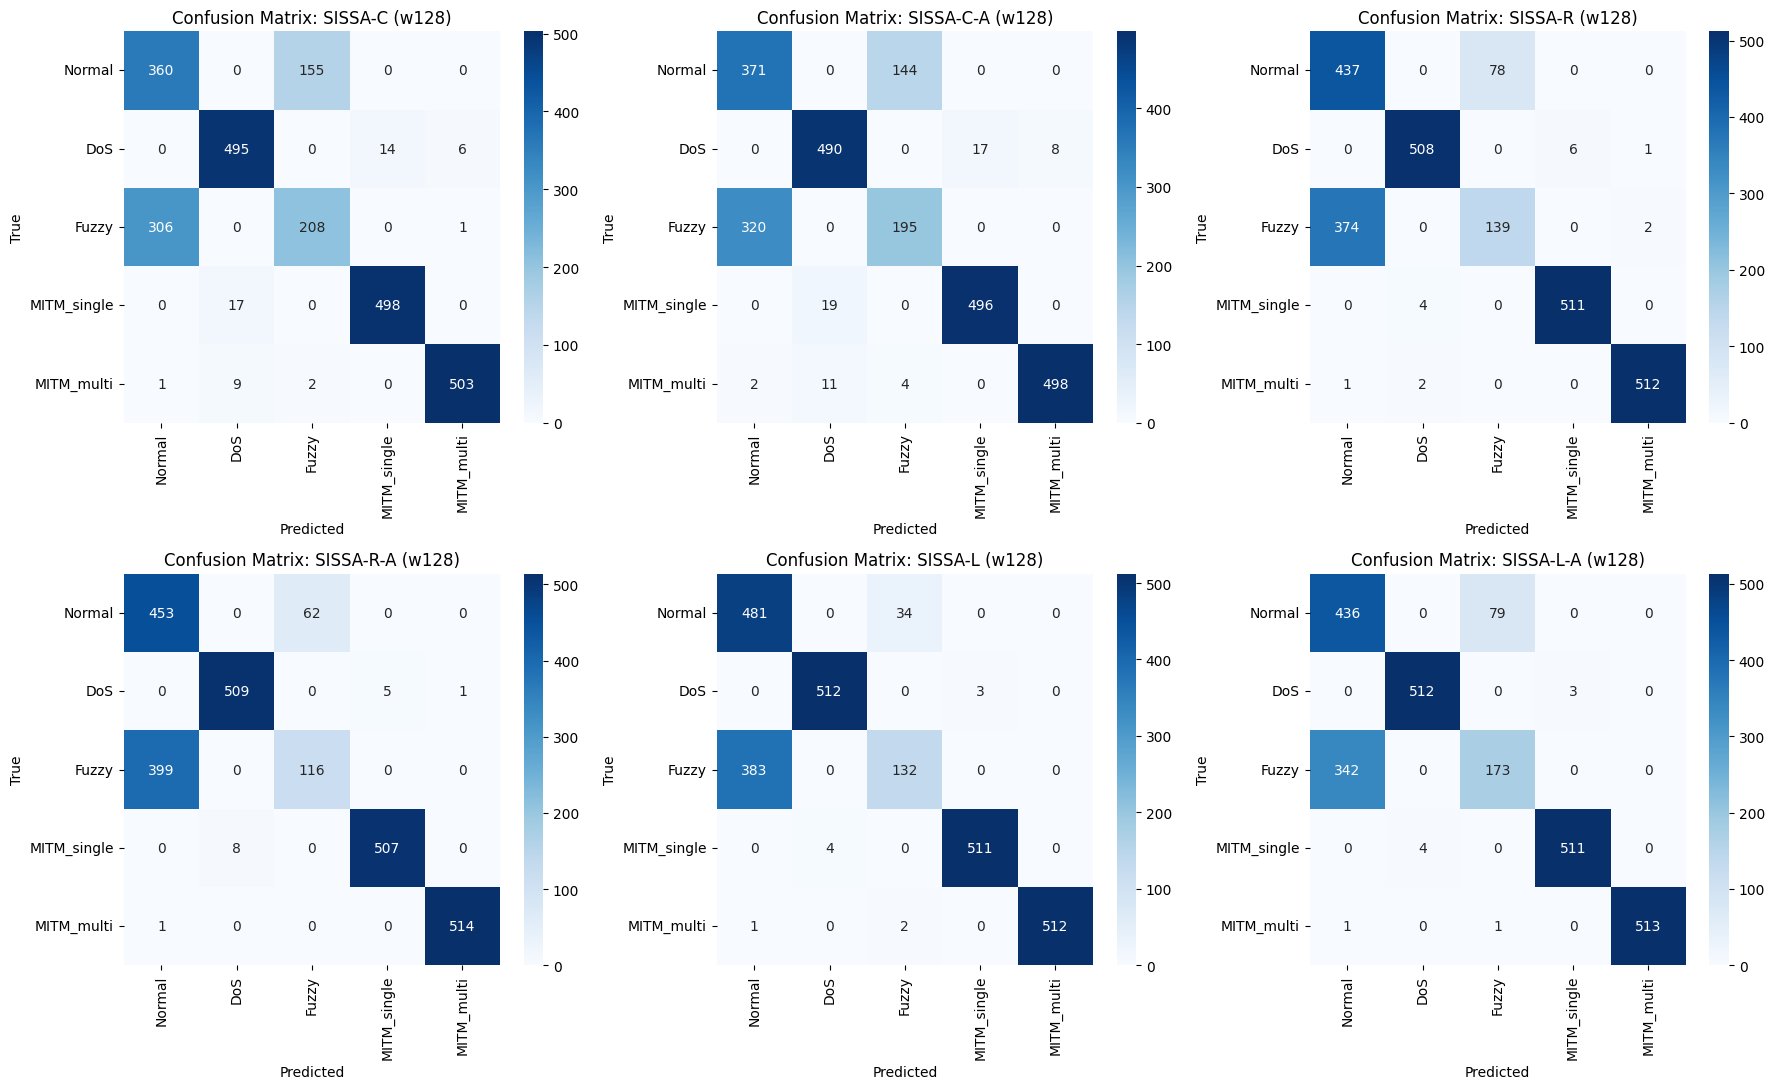

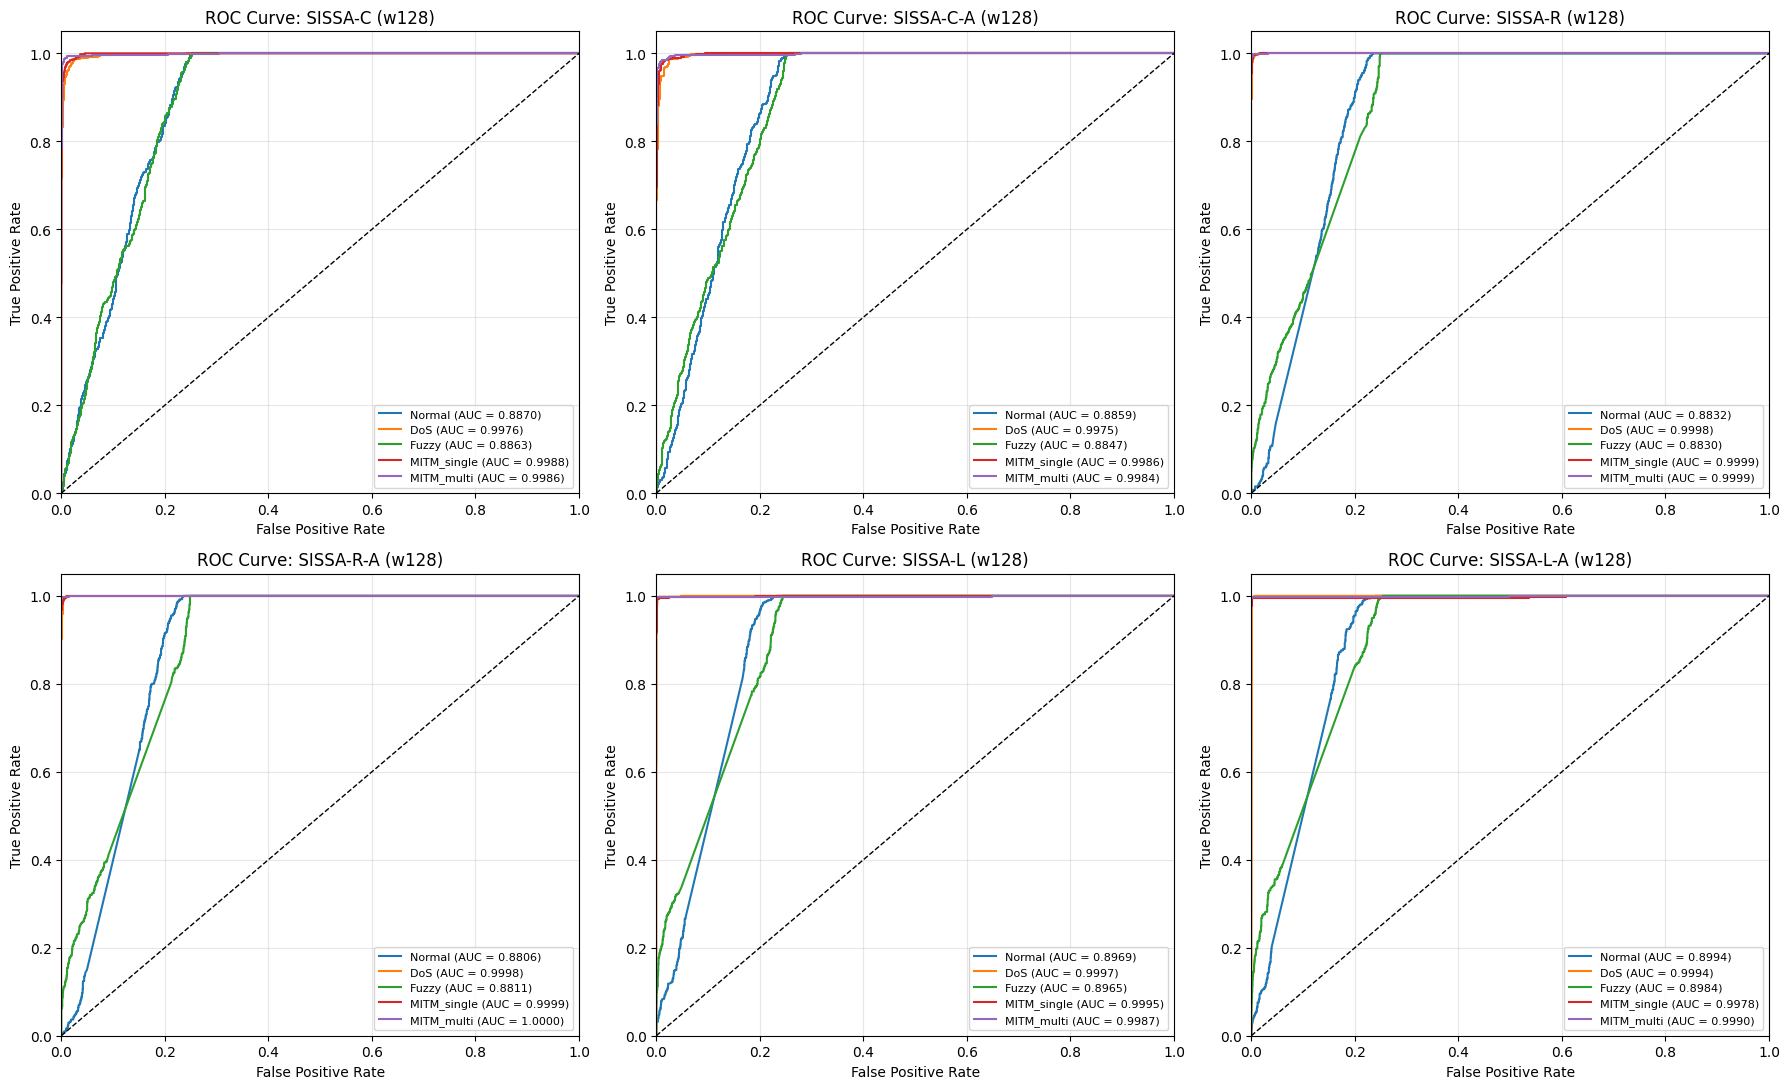

In [10]:
# Figuras 11 e 12: Matrizes de Confusão e Curvas ROC / AUC para os 6 modelos (w128)
import seaborn as sns
from sklearn.metrics import roc_curve, auc

basic_cfg = yaml.load(open("config/basic.yml", "r"))
class_names = basic_cfg["Preprocessor"]["class_names"]
n_classes = len(class_names)

# Figura 11: Matrizes de Confusão
fig_cm, axes_cm = plt.subplots(2, 3, figsize=(18, 11))
for ax, m_name in zip(axes_cm.flat, MODELS):
    cm = np.load(f"results/test_result/{m_name}_w{target_w}/cm.npy")
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"Confusion Matrix: {m_name} (w{target_w})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

# Figura 12: Curvas ROC e AUC (usando probabilidades do softmax)
fig_roc, axes_roc = plt.subplots(2, 3, figsize=(18, 11))
for ax, m_name in zip(axes_roc.flat, MODELS):
    res_dir = f"results/test_result/{m_name}_w{target_w}"
    y_true = np.load(f"{res_dir}/true.npy")
    y_probs = np.load(f"{res_dir}/probs.npy")

    for c_idx, c_name in enumerate(class_names):
        fpr, tpr, _ = roc_curve((y_true == c_idx).astype(int), y_probs[:, c_idx])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{c_name} (AUC = {roc_auc:.4f})")

    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"ROC Curve: {m_name} (w{target_w})")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


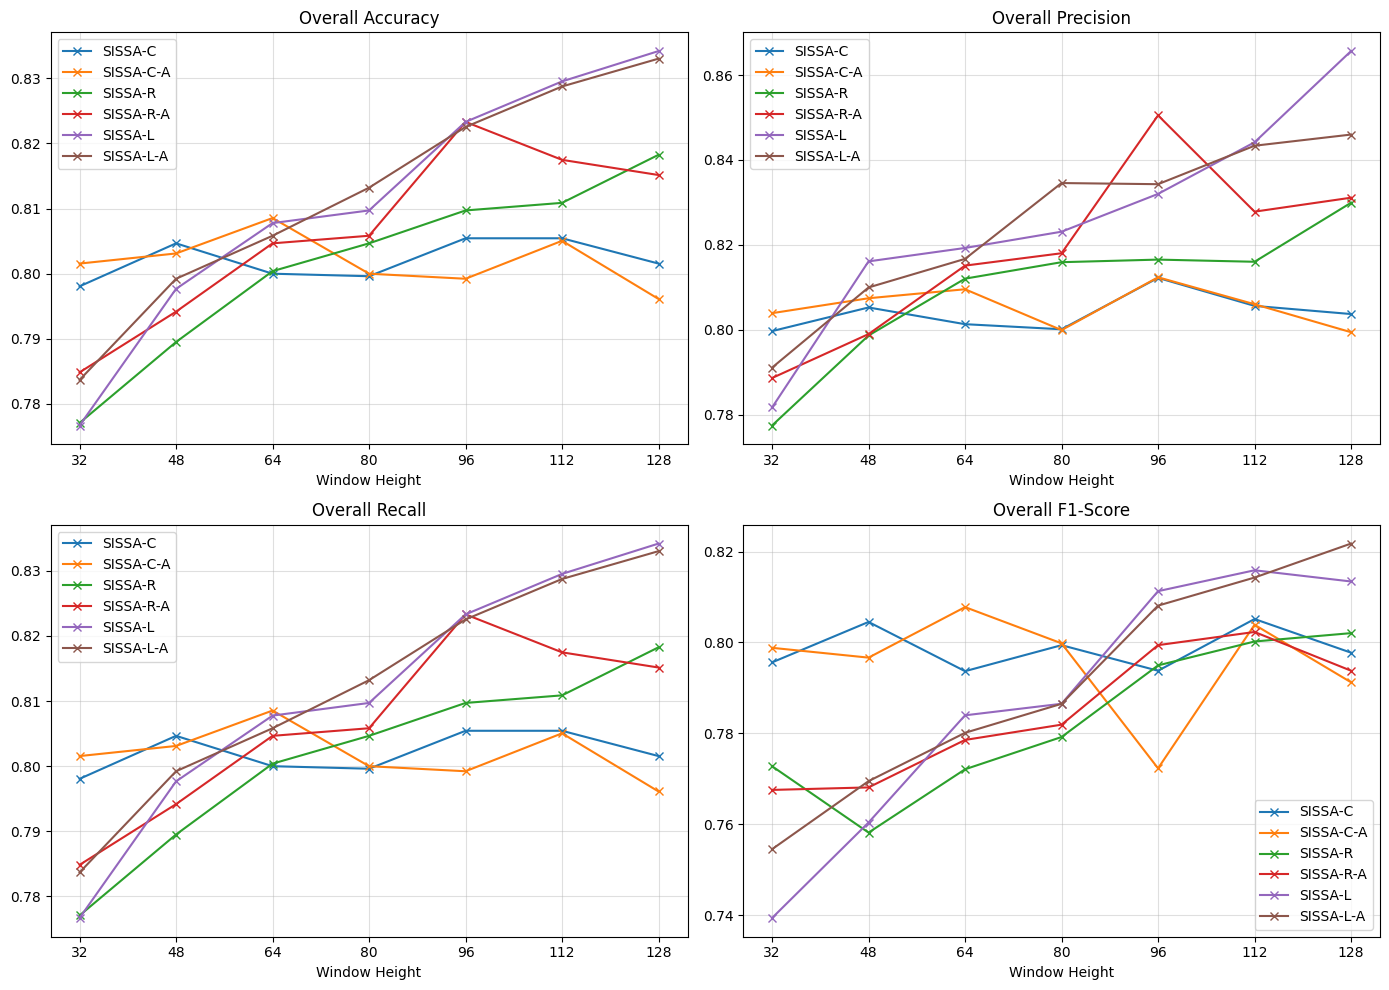

In [11]:
# Figura 13: Accuracy, Precision, Recall e F1-Score variando o tamanho da janela
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

metrics_by_w = {metric: {m: [] for m in MODELS} for metric in ["Overall Accuracy", "Overall Precision", "Overall Recall", "Overall F1-Score"]}

for w in WINDOW_SIZES:
    for m_name in MODELS:
        res_dir = f"results/test_result/{m_name}_w{w}"
        y_true = np.load(f"{res_dir}/true.npy")
        y_pred = np.load(f"{res_dir}/pred.npy")
        metrics_by_w["Overall Accuracy"][m_name].append(accuracy_score(y_true, y_pred))
        metrics_by_w["Overall Precision"][m_name].append(precision_score(y_true, y_pred, average="macro", zero_division=0))
        metrics_by_w["Overall Recall"][m_name].append(recall_score(y_true, y_pred, average="macro", zero_division=0))
        metrics_by_w["Overall F1-Score"][m_name].append(f1_score(y_true, y_pred, average="macro", zero_division=0))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (metric_name, m_dict) in zip(axes.flat, metrics_by_w.items()):
    for m_name in MODELS:
        ax.plot(WINDOW_SIZES, m_dict[m_name], marker="x", label=m_name)
    ax.set_title(metric_name)
    ax.set_xlabel("Window Height")
    ax.set_xticks(WINDOW_SIZES)
    ax.grid(True, alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()


In [12]:
# Tabelas III, IV e V adaptadas ao dataset de Kim et al.
import pandas as pd
from IPython.display import display

def binary_metrics(y_true_bin, y_pred_bin):
    tp = np.sum((y_true_bin == 1) & (y_pred_bin == 1))
    tn = np.sum((y_true_bin == 0) & (y_pred_bin == 0))
    fp = np.sum((y_true_bin == 0) & (y_pred_bin == 1))
    fn = np.sum((y_true_bin == 1) & (y_pred_bin == 0))
    acc = (tp + tn) / (tp + tn + fp + fn)
    pre = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * pre * rec) / (pre + rec) if (pre + rec) > 0 else 0.0
    return round(acc, 3), round(pre, 3), round(rec, 3), round(f1, 3)

rows_t3, rows_t4 = [], []
for m_name in MODELS:
    res_dir = f"results/test_result/{m_name}_w{target_w}"
    y_true = np.load(f"{res_dir}/true.npy")
    y_pred = np.load(f"{res_dir}/pred.npy")

    # Tabela III (agrupada): Normal (0) vs Attack (1..4)
    y_t3 = np.where(y_true == 0, 0, 1)
    p_t3 = np.where(y_pred == 0, 0, 1)
    for idx, cname in enumerate(["Normal", "Attack"]):
        acc, pre, rec, f1 = binary_metrics((y_t3 == idx).astype(int), (p_t3 == idx).astype(int))
        rows_t3.append({"Model": m_name, "Class": cname, "Acc": acc, "Pre": pre, "Recall": rec, "F1": f1})

    # Tabela IV: Todas as 5 classes do Kim
    for idx, cname in enumerate(class_names):
        acc, pre, rec, f1 = binary_metrics((y_true == idx).astype(int), (y_pred == idx).astype(int))
        rows_t4.append({"Model": m_name, "Class": cname, "Acc": acc, "Pre": pre, "Recall": rec, "F1": f1})

print(f"=== Tabela III: Comparação por Categoria — Normal vs Attack (w{target_w}) ===")
display(pd.DataFrame(rows_t3))

print(f"\n=== Tabela IV: Comparação por Classe — 5 classes (w{target_w}) ===")
display(pd.DataFrame(rows_t4))

print("\n=== Tabela V: Características e Recursos Computacionais ===")
display(pd.DataFrame(overhead_records))


=== Tabela III: Comparação por Categoria — Normal vs Attack (w128) ===


,Model,Class,Acc,Pre,Recall,F1
0,SISSA-C,Normal,0.821,0.540,0.699,0.609
1,SISSA-C,Attack,0.821,0.919,0.851,0.884
2,SISSA-C-A,Normal,0.819,0.535,0.720,0.614
3,SISSA-C-A,Attack,0.819,0.923,0.844,0.882
4,SISSA-R,Normal,0.824,0.538,0.849,0.659
5,SISSA-R,Attack,0.824,0.956,0.818,0.882
6,SISSA-R-A,Normal,0.821,0.531,0.880,0.662
7,SISSA-R-A,Attack,0.821,0.964,0.806,0.878
8,SISSA-L,Normal,0.838,0.556,0.934,0.697
9,SISSA-L,Attack,0.838,0.980,0.814,0.889



=== Tabela IV: Comparação por Classe — 5 classes (w128) ===


,Model,Class,Acc,Pre,Recall,F1
0,SISSA-C,Normal,0.821,0.540,0.699,0.609
1,SISSA-C,DoS,0.982,0.950,0.961,0.956
2,SISSA-C,Fuzzy,0.820,0.570,0.404,0.473
3,SISSA-C,MITM_single,0.988,0.973,0.967,0.970
4,SISSA-C,MITM_multi,0.993,0.986,0.977,0.981
5,SISSA-C-A,Normal,0.819,0.535,0.720,0.614
6,SISSA-C-A,DoS,0.979,0.942,0.951,0.947
7,SISSA-C-A,Fuzzy,0.818,0.569,0.379,0.455
8,SISSA-C-A,MITM_single,0.986,0.967,0.963,0.965
9,SISSA-C-A,MITM_multi,0.990,0.984,0.967,0.976



=== Tabela V: Características e Recursos Computacionais ===


,Windows,Model,Total Params,Params size (MB),Input size (MB),Forward/Backward Pass size (MB),Total size (MB),Time Cost (s)
0,w32,SISSA-C,72838,0.29,0.00,1.00,1.29,0.0016
1,w32,SISSA-C-A,73654,0.29,0.00,1.00,1.30,0.0016
2,w32,SISSA-R,579653,2.32,0.00,0.07,2.40,0.0010
3,w32,SISSA-R-A,629189,2.52,0.00,0.17,2.69,0.0015
4,w32,SISSA-L,2922821,11.69,0.00,0.14,11.84,0.0018
5,w32,SISSA-L-A,3120197,12.48,0.00,0.34,12.82,0.0025
6,w48,SISSA-C,73254,0.29,0.00,1.01,1.30,0.0011
7,w48,SISSA-C-A,74070,0.30,0.00,1.01,1.31,0.0016
8,w48,SISSA-R,844261,3.38,0.00,0.12,3.50,0.0010
9,w48,SISSA-R-A,893797,3.58,0.00,0.27,3.85,0.0015


## 3. Sincronização final com o Google Drive
Garante que todos os resultados, logs e pesos finais estejam salvos em `/content/drive/MyDrive/SISSA_kim_results`.


In [13]:
if os.path.exists(LOCAL_RESULTS):
    os.makedirs(DRIVE_RESULTS, exist_ok=True)
    !rsync -ah --info=progress2 "{LOCAL_RESULTS}/" "{DRIVE_RESULTS}/"
    print(f"Sucesso! Resultados sincronizados em: {DRIVE_RESULTS}")
else:
    print(f"Erro: A pasta de origem {LOCAL_RESULTS} não foi encontrada.")


              0   0%    0.00kB/s    0:00:00 (xfr#0, to-chk=0/571)
Sucesso! Resultados sincronizados em: /content/drive/MyDrive/SISSA_kim_results
